# Titanic Survival Prediction — Model Training

## Objective

Train a Logistic Regression classification model to predict
whether a Titanic passenger survived.

We will:
1. Load and split the dataset.
2. Apply the preprocessing pipeline.
3. Train Logistic Regression.
4. Evaluate predictions on validation data.


In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split

train_df = pd.read_csv("../data/raw/train.csv")

features = [
    "Pclass",
    "Sex",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "Embarked"
]

X = train_df[features]
y = train_df["Survived"]

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features = [
    "Pclass", "Age", "SibSp", "Parch", "Fare"
]

categorical_features = [
    "Sex", "Embarked"
]

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [4]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [5]:
y_pred = model.predict(X_val)

print("First 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 actual values:")
print(y_val.iloc[:10].values)

First 10 predictions:
[0 0 0 0 1 0 1 0 0 0]

First 10 actual values:
[0 0 1 0 1 1 1 0 0 0]


In [6]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_val, y_pred)

print(f"Validation Accuracy: {accuracy:.2%}")

Validation Accuracy: 80.45%


## Model Evaluation — Confusion Matrix

A confusion matrix helps us understand correct and incorrect
predictions for each survival class.

In [7]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[98 12]
 [23 46]]


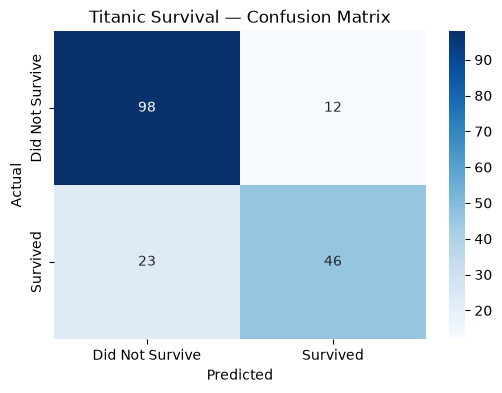

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Titanic Survival — Confusion Matrix")

plt.show()

In [9]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred,
    target_names=["Did Not Survive", "Survived"]
))

                 precision    recall  f1-score   support

Did Not Survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_val)

print("Baseline Accuracy:",
      f"{accuracy_score(y_val, baseline_pred):.2%}")

print("Logistic Regression Accuracy:",
      f"{accuracy_score(y_val, y_pred):.2%}")

print("\nBaseline Classification Report:")
print(classification_report(
    y_val,
    baseline_pred,
    zero_division=0
))

Baseline Accuracy: 61.45%
Logistic Regression Accuracy: 80.45%

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.61      1.00      0.76       110
           1       0.00      0.00      0.00        69

    accuracy                           0.61       179
   macro avg       0.31      0.50      0.38       179
weighted avg       0.38      0.61      0.47       179



## Model Interpretation — Feature Coefficients

We examine Logistic Regression coefficients to understand
how passenger features influence predicted survival.

In [11]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

print(feature_names)

['num__Pclass' 'num__Age' 'num__SibSp' 'num__Parch' 'num__Fare'
 'cat__Sex_female' 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_Q'
 'cat__Embarked_S']


In [12]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [14]:
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
logistic_model = model.named_steps["classifier"]

coefficients = logistic_model.coef_[0]

print(coefficients)

[-0.92197224 -0.50281488 -0.2606066  -0.06642413  0.10026908  1.29944383
 -1.32071816  0.03224661  0.30478416 -0.3583051 ]


In [16]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(model.named_steps["classifier"])

print("The Logistic Regression model is fitted!")

The Logistic Regression model is fitted!


In [17]:
feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = model.named_steps[
    "classifier"
].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

print(feature_importance)

           Feature  Coefficient
5  cat__Sex_female     1.299444
8  cat__Embarked_Q     0.304784
4        num__Fare     0.100269
7  cat__Embarked_C     0.032247
3       num__Parch    -0.066424
2       num__SibSp    -0.260607
9  cat__Embarked_S    -0.358305
1         num__Age    -0.502815
0      num__Pclass    -0.921972
6    cat__Sex_male    -1.320718
